In [ ]:
import pandas as pd
import numpy as np
import cvxpy as cp
from matplotlib import pyplot as plt
_text_replacements = {'\u043f\u0440\u0438\u043c\u0435\u043d\u0438\u043c \u0444\u0443\u043d\u043a\u0446\u0438\u044e read_csv() \u0438 \u043f\u043e\u0441\u043c\u043e\u0442\u0440\u0438\u043c \u043d\u0430 \u043f\u0435\u0440\u0432\u044b\u0435 \u0442\u0440\u0438 \u0437\u0430\u043f\u0438\u0441\u0438 \u0444\u0430\u0439\u043b\u0430 uni_and_dorms.csv': 'Use read_csv() and preview the first five rows of uni_and_dorms.csv', '\u0441\u0442\u0430\u043d\u0446\u0438\u0438 \u0432 \u043f\u0440\u0435\u0434\u0435\u043b\u0430\u0445 \u041a\u043e\u043b\u044c\u0446\u0435\u0432\u043e\u0439 \u043b\u0438\u043d\u0438': 'Stations within the Circle Line', '\u0441\u0442\u0430\u043d\u0446\u0438\u0438 \u043c\u0435\u0436\u0434\u0443 \u041a\u043e\u043b\u044c\u0446\u0435\u0432\u043e\u0439 \u043b\u0438\u043d\u0438\u0435\u0439 \u0438 \u0411\u043e\u043b\u044c\u0448\u043e\u0439 \u041a\u043e\u043b\u044c\u0446\u0435\u0432\u043e\u0439 \u043b\u0438\u043d\u0438\u0435\u0439': 'Stations between the Circle Line and the Big Circle Line', '\u0412\u0441\u0435\u0433\u043e \u0441\u0442\u0430\u043d\u0446\u0438\u0439 \u0432 \u0440\u0430\u0441\u0441\u043c\u043e\u0442\u0440\u0435\u043d\u0438\u0438': 'Total stations included:', '\u0412\u0441\u0435\u0433\u043e \u043b\u0438\u043d\u0438\u0439 \u0432 \u0440\u0430\u0441\u0441\u043c\u043e\u0442\u0440\u0435\u043d\u0438\u0438': 'Total lines included:', '\u043c\u0430\u043a\u0441\u0438\u043c\u0438\u0437\u0438\u0440\u0443\u0435\u043c \u0441\u0443\u043c\u043c\u0430\u0440\u043d\u0443\u044e \u043f\u0440\u0438\u0431\u044b\u043b\u044c': 'Maximize total profit', '\u043e\u0433\u0440\u0430\u043d\u0438\u0447\u0435\u043d\u0438\u0435 \u0431\u044e\u0434\u0436\u0435\u0442\u0430 \u043d\u0430 \u0440\u0435\u043a\u043b\u0430\u043c\u0443': 'Advertising budget constraint', '\u043e\u0433\u0440\u0430\u043d\u0438\u0447\u0435\u043d\u0438\u0435 \u043d\u0430 \u043c\u0430\u043a\u0441\u0438\u043c\u0430\u043b\u044c\u043d\u043e \u0432\u043e\u0437\u043c\u043e\u0436\u043d\u043e\u0435 \u043a\u043e\u043b\u0438\u0447\u0435\u0441\u0442\u0432\u043e \u043c\u0435\u0441\u0442 \u0434\u043b\u044f \u0441\u0442\u0443\u0434\u0435\u043d\u0442\u043e\u0432 \u043d\u0430 \u043a\u0443\u0440\u0441\u0430\u0445': 'Maximum student capacity constraint', '\u043e\u0433\u0440\u0430\u043d\u0438\u0447\u0435\u043d\u0438\u0435 \u043d\u0430 \u043c\u0430\u043a\u0441\u0438\u043c\u0430\u043b\u044c\u043d\u043e\u0435 \u043a\u043e\u043b\u0438\u0447\u0435\u0441\u0442\u0432\u043e \u0437\u0430\u0434\u0435\u0439\u0441\u0442\u0432\u043e\u0432\u0430\u043d\u043d\u044b\u0445 \u0431\u0430\u043d\u043d\u0435\u0440\u043e\u0432 \u043d\u0430 \u0441\u0442\u0430\u043d\u0446\u0438\u0438': 'Maximum number of advertising banners per station', '\u043e\u0433\u0440\u0430\u043d\u0438\u0447\u0435\u043d\u0438\u0435 \u043d\u0430 \u043c\u0438\u043d\u0438\u043c\u0430\u043b\u044c\u043d\u043e\u0435 \u043a\u043e\u043b\u0438\u0447\u0435\u0441\u0442\u0432\u043e \u0437\u0430\u0434\u0435\u0439\u0441\u0442\u0432\u043e\u0432\u0430\u043d\u043d\u044b\u0445 \u0431\u0430\u043d\u043d\u0435\u0440\u043e\u0432 \u043d\u0430 \u0441\u0442\u0430\u043d\u0446\u0438\u0438': 'Minimum number of advertising banners per station', '\u0435\u0441\u043b\u0438 \u043f\u0430\u0441\u0441\u0430\u0436\u0438\u0440\u043e\u043f\u043e\u0442\u043e\u043a 0, \u0442\u043e \u043c\u044b \u043d\u0435 \u0431\u0443\u0434\u0435\u043c \u0440\u0430\u0437\u043c\u0435\u0449\u0430\u0442\u044c \u0440\u0435\u043a\u043b\u0430\u043c\u0443 \u043d\u0430 \u0441\u0442\u0430\u043d\u0446\u0438\u0438': 'Do not advertise at stations with zero passenger traffic', '\u043c\u044b \u0445\u043e\u0442\u0438\u043c \u0440\u0430\u0437\u043c\u0435\u0449\u0430\u0442\u044c \u043a\u0430\u043a \u043c\u0438\u043d\u0438\u043c\u0443\u043c 1 \u0440\u0435\u043a\u043b\u0430\u043c\u0443 \u043d\u0430 \u043a\u0430\u0436\u0434\u043e\u0439 \u043b\u0438\u043d\u0438\u0438 \u043c\u0435\u0442\u0440\u043e\u043f\u043e\u043b\u0438\u0442\u0435\u043d\u0430': 'Place at least one advertisement on each metro line', '\u0421\u0442\u0430\u043d\u0446\u0438\u0438, \u043d\u0430 \u043a\u043e\u0442\u043e\u0440\u044b\u0445 \u043d\u0435\u043e\u0431\u0445\u043e\u0434\u0438\u043c\u043e \u0440\u0430\u0441\u043f\u043e\u043b\u043e\u0436\u0438\u0442\u044c \u0440\u0435\u043a\u043b\u0430\u043c\u0443:': 'Stations selected for advertising:', '\u0421\u0443\u043c\u043c\u0430\u0440\u043d\u0430\u044f \u043f\u043e\u043b\u0443\u0447\u0435\u043d\u043d\u0430\u044f \u043f\u0440\u0438\u0431\u044b\u043b\u044c (\u0432 \u0440\u0443\u0431\u043b\u044f\u0445):': 'Total profit (RUB):', '\u0420\u0430\u0441\u043f\u043e\u043b\u043e\u0436\u0435\u043d\u0438\u0435 \u0440\u0435\u043a\u043b\u0430\u043c\u044b \u043d\u0430 \u0441\u0442\u0430\u043d\u0446\u0438\u044f\u0445 \u043c\u0435\u0442\u0440\u043e \u0434\u043b\u044f \u0431\u0430\u0437\u043e\u0432\u043e\u0433\u043e \u0430\u043b\u0433\u043e\u0440\u0438\u0442\u043c\u0430': 'Advertising allocation across metro stations: baseline model', '\u0420\u0430\u0441\u043f\u043e\u043b\u043e\u0436\u0435\u043d\u0438\u0435 \u0440\u0435\u043a\u043b\u0430\u043c\u044b \u043d\u0430 \u0441\u0442\u0430\u043d\u0446\u0438\u044f\u0445 \u043c\u0435\u0442\u0440\u043e \u0432 \u0441\u043b\u0443\u0447\u0430\u0435 \u0443\u0432\u0435\u043b\u0438\u0447\u0435\u043d\u0438\u044f \u043f\u043e\u0442\u0435\u043d\u0446\u0438\u0430\u043b\u044c\u043d\u043e\u0433\u043e \u043a\u043e\u043b\u0438\u0447\u0435\u0441\u0442\u0432\u0430 \u0441\u0442\u0443\u0434\u0435\u043d\u0442\u043e\u0432': 'Advertising allocation with increased student capacity', '\u0420\u0430\u0441\u043f\u043e\u043b\u043e\u0436\u0435\u043d\u0438\u0435 \u0440\u0435\u043a\u043b\u0430\u043c\u044b \u043d\u0430 \u0441\u0442\u0430\u043d\u0446\u0438\u044f\u0445 \u043c\u0435\u0442\u0440\u043e \u043f\u0440\u0438 \u0438\u0437\u043c\u0435\u043d\u0435\u043d\u0438\u0438 \u0441\u0442\u043e\u0438\u043c\u043e\u0441\u0442\u0438 \u0440\u0435\u043a\u043b\u0430\u043c\u044b': 'Advertising allocation with revised advertising costs', '\u0420\u0430\u0441\u043f\u043e\u043b\u043e\u0436\u0435\u043d\u0438\u0435 \u0440\u0435\u043a\u043b\u0430\u043c\u044b \u043d\u0430 \u0441\u0442\u0430\u043d\u0446\u0438\u044f\u0445 \u043c\u0435\u0442\u0440\u043e \u0434\u043b\u044f \u0441\u043d\u0438\u0436\u0435\u043d\u043d\u043e\u0433\u043e \u0431\u044e\u0434\u0436\u0435\u0442\u0430 \u043d\u0430 \u0440\u0435\u043a\u043b\u0430\u043c\u0443': 'Advertising allocation with a reduced advertising budget', '\u0420\u0430\u0441\u043f\u043e\u043b\u043e\u0436\u0435\u043d\u0438\u0435 \u0440\u0435\u043a\u043b\u0430\u043c\u044b \u043d\u0430 \u0441\u0442\u0430\u043d\u0446\u0438\u044f\u0445 \u043c\u0435\u0442\u0440\u043e \u0434\u043b\u044f \u0443\u0441\u043b\u043e\u0436\u043d\u0435\u043d\u043d\u043e\u0433\u043e \u0430\u043b\u0433\u043e\u0440\u0438\u0442\u043c\u0430': 'Advertising allocation across metro stations: extended model', '\u041d\u0430\u0437\u0432\u0430\u043d\u0438\u0435': 'Name', '\u041c\u0435\u0442\u0440\u043e': 'Metro', '\u0421\u0442\u0430\u043d\u0446\u0438\u044f \u043c\u0435\u0442\u0440\u043e\u043f\u043e\u043b\u0438\u0442\u0435\u043d\u0430': 'Metro station', '\u041b\u0438\u043d\u0438\u044f': 'Line', '\u0413\u043e\u0434': 'Year', '\u041a\u0432\u0430\u0440\u0442\u0430\u043b': 'Quarter', '\u0412\u0445\u043e\u0434\u044b \u043f\u0430\u0441\u0441\u0430\u0436\u0438\u0440\u043e\u0432': 'Incoming passengers', '\u0412\u044b\u0445\u043e\u0434\u044b \u043f\u0430\u0441\u0441\u0430\u0436\u0438\u0440\u043e\u0432': 'Outgoing passengers', '\u043a\u0432\u0430\u0440\u0442\u0430\u043b': 'quarter', '\u0412\u0414\u041d\u0425': 'VDNKh', '\u0426\u0421\u041a\u0410': 'CSKA'}
_latin_characters = {'\u0430': 'a', '\u0431': 'b', '\u0432': 'v', '\u0433': 'g', '\u0434': 'd', '\u0435': 'e', '\u0451': 'yo', '\u0436': 'zh', '\u0437': 'z', '\u0438': 'i', '\u0439': 'y', '\u043a': 'k', '\u043b': 'l', '\u043c': 'm', '\u043d': 'n', '\u043e': 'o', '\u043f': 'p', '\u0440': 'r', '\u0441': 's', '\u0442': 't', '\u0443': 'u', '\u0444': 'f', '\u0445': 'kh', '\u0446': 'ts', '\u0447': 'ch', '\u0448': 'sh', '\u0449': 'shch', '\u044a': '', '\u044b': 'y', '\u044c': '', '\u044d': 'e', '\u044e': 'yu', '\u044f': 'ya', '\u0410': 'A', '\u0411': 'B', '\u0412': 'V', '\u0413': 'G', '\u0414': 'D', '\u0415': 'E', '\u0401': 'Yo', '\u0416': 'Zh', '\u0417': 'Z', '\u0418': 'I', '\u0419': 'Y', '\u041a': 'K', '\u041b': 'L', '\u041c': 'M', '\u041d': 'N', '\u041e': 'O', '\u041f': 'P', '\u0420': 'R', '\u0421': 'S', '\u0422': 'T', '\u0423': 'U', '\u0424': 'F', '\u0425': 'Kh', '\u0426': 'Ts', '\u0427': 'Ch', '\u0428': 'Sh', '\u0429': 'Shch', '\u042a': '', '\u042b': 'Y', '\u042c': '', '\u042d': 'E', '\u042e': 'Yu', '\u042f': 'Ya'}

# Normalize Russian column names and text values to English or Latin script.
def normalize_text(value):
    if not isinstance(value, str):
        return value
    for source, target in sorted(_text_replacements.items(), key=lambda pair: -len(pair[0])):
        value = value.replace(source, target)
    return ''.join(_latin_characters.get(char, char) for char in value)

def normalize_dataframe(frame):
    frame = frame.copy()
    frame.columns = [normalize_text(column) for column in frame.columns]
    for column in frame.select_dtypes(include=['object', 'string']).columns:
        frame[column] = frame[column].map(normalize_text)
    return frame


# Problem statement

**Problem:** Company X offers paid courses to students at leading universities. It needs to decide which metro stations to advertise at and how many advertisements to place to maximize student acquisition.

*Student acquisition* refers to the number of students who purchase Company X's services as a result of advertising in the metro.

**Objective:** Find the optimal advertising locations and quantities within the company's budget to maximize profit.

# Data import

In [ ]:
pd.options.mode.chained_assignment = None
# Use read_csv() and preview the first five rows of uni_and_dorms.csv
url = 'https://raw.githubusercontent.com/TatianaSoboleva/-/main/uni_and_dorms.csv'
instit = pd.read_csv( url)
instit = normalize_dataframe(instit)
instit.head(5)

,Name,Metro
0,Moskovskiy gosudarstvennyy universitet imeni M...,Universitet
1,Moskovskiy gosudarstvennyy universitet imeni M...,Biblioteka imeni Lenina
2,Moskovskiy gosudarstvennyy universitet imeni M...,Okhotnyy ryad
3,Moskovskiy gosudarstvennyy tekhnicheskiy univers...,Baumanskaya
4,Moskovskiy gosudarstvennyy tekhnicheskiy univers...,Rechnoy vokzal


In [ ]:
url = 'https://raw.githubusercontent.com/TatianaSoboleva/-/main/metro_ba.csv'
metro = pd.read_csv( url, delimiter = ';')
metro = normalize_dataframe(metro)
metro.head(5)

,NameOfStation,Line,Year,Quarter,IncomingPassengers,OutgoingPassengers,global_id,Unnamed: 7
0,Metro station,Line,Year,Quarter,Incoming passengers,Outgoing passengers,global_id,NaN
1,Mitino,Arbatsko-Pokrovskaya liniya,2021,I quarter,1913498,1829031,1138975996,NaN
2,Volokolamskaya,Arbatsko-Pokrovskaya liniya,2021,I quarter,1236714,1222309,1138975997,NaN
3,Strogino,Arbatsko-Pokrovskaya liniya,2021,I quarter,1938816,1903731,1138975999,NaN
4,Krylatskoe,Arbatsko-Pokrovskaya liniya,2021,I quarter,1849616,1818208,1138976000,NaN


# Data preprocessing

For this project, we use Moscow Metro passenger traffic data for the third quarter of 2023. This period was chosen to use the most recent data available at the time of the study and reflect the passenger traffic patterns prevailing then. We assume that seasonality is negligible and will not materially affect the conclusions.

We perform the following operations:

1. Handle missing values.
2. Divide metro stations into three zones based on advertising costs.
3. Estimate the conversion of passenger traffic into course purchases based on the number of universities and student dormitories near each station.
4. Rank metro stations by passenger traffic.

In [ ]:
metro_actual = metro[metro['Year'] == '2023']
metro_actual_2 = metro_actual[metro_actual['Quarter'] == 'III quarter']

In [ ]:
def f(row):
    if row['Line'] == 'Sokolnicheskaya liniya':
        return 1
    elif row['Line'] == 'Zamoskvoretskaya liniya':
        return 2
    elif row['Line'] == 'Arbatsko-Pokrovskaya liniya':
        return 3
    elif row['Line'] == 'Filyovskaya liniya':
        return 4
    elif row['Line'] == 'Koltsevaya liniya':
        return 5
    elif row['Line'] == 'Kaluzhsko-Rizhskaya liniya':
        return 6
    elif row['Line'] == 'Tagansko-Krasnopresnenskaya liniya':
        return 7
    elif row['Line'] == 'Kalininskaya liniya':
        return 8
    elif row['Line'] == 'Serpukhovsko-Timiryazevskaya liniya':
        return 9
    elif row['Line'] == 'Butovskaya liniya Lyogkogo metro':
        return 10
    elif row['Line'] == 'Lyublinsko-Dmitrovskaya liniya':
        return 11
    elif row['Line'] == 'Nekrasovskaya liniya':
        return 12
    elif row['Line'] == 'Solntsevskaya liniya':
        return 13
    elif row['Line'] == 'Moskovskaya monorelsovaya transportnaya sistema':
        return 14
    elif row['Line'] == 'Moskovskoe tsentralnoe koltso':
        return 15
    elif row['Line'] == 'Bolshaya koltsevaya liniya':
        return 16
    elif row['Line'] == 'Kakhovskaya liniya':
        return 17

metro_actual_2['Line_id'] = metro_actual_2.apply(f, axis=1)

Note that the numerical values in the table have the `object` data type:

In [ ]:
metro_actual_2.dtypes

NameOfStation          object
Line                   object
Year                   object
Quarter                object
IncomingPassengers     object
OutgoingPassengers     object
global_id              object
Unnamed: 7            float64
Line_id                 int64
dtype: object

In [ ]:
metro_actual_2[['IncomingPassengers', 'OutgoingPassengers']] = metro_actual_2[['IncomingPassengers','OutgoingPassengers']].astype(float)
metro_actual_2.dtypes

NameOfStation          object
Line                   object
Year                   object
Quarter                object
IncomingPassengers    float64
OutgoingPassengers    float64
global_id              object
Unnamed: 7            float64
Line_id                 int64
dtype: object

Some interchange stations have zero passenger counts. We correct these values below:

In [ ]:
metro_actual_2[metro_actual_2['IncomingPassengers'] == 0]

,NameOfStation,Line,Year,Quarter,IncomingPassengers,OutgoingPassengers,global_id,Unnamed: 7,Line_id
2853,Ulitsa Starokachalovskaya,Butovskaya liniya Lyogkogo metro,2023,III quarter,0.0,0.0,2625907155,NaN,10
2868,Tverskaya,Zamoskvoretskaya liniya,2023,III quarter,0.0,0.0,2625907170,NaN,2
2869,Teatralnaya,Zamoskvoretskaya liniya,2023,III quarter,0.0,0.0,2625907171,NaN,2
2875,Kashirskaya,Zamoskvoretskaya liniya,2023,III quarter,0.0,0.0,2625907177,NaN,2
3004,Biblioteka imeni Lenina,Sokolnicheskaya liniya,2023,III quarter,0.0,0.0,2625907333,NaN,1
3087,Tretyakovskaya,Kaluzhsko-Rizhskaya liniya,2023,III quarter,0.0,0.0,2630091425,NaN,6
3106,Petrovsko-Razumovskaya,Serpukhovsko-Timiryazevskaya liniya,2023,III quarter,0.0,0.0,2630091575,NaN,9
3109,Kitay-gorod,Tagansko-Krasnopresnenskaya liniya,2023,III quarter,0.0,0.0,2630091643,NaN,7
3111,Kievskaya,Filyovskaya liniya,2023,III quarter,0.0,0.0,2630091656,NaN,4


In [ ]:
metro_actual_2.loc[metro_actual_2['NameOfStation'] == 'Ulitsa Starokachalovskaya', 'IncomingPassengers'] = metro_actual_2[metro_actual_2['NameOfStation'] == 'Bulvar Dmitriya Donskogo']['IncomingPassengers'][2994]
metro_actual_2.loc[metro_actual_2['NameOfStation'] == 'Ulitsa Starokachalovskaya', 'OutgoingPassengers'] = metro_actual_2[metro_actual_2['NameOfStation'] == 'Bulvar Dmitriya Donskogo']['OutgoingPassengers'][2994]

metro_actual_2.loc[metro_actual_2['NameOfStation'] == 'Tverskaya', 'IncomingPassengers'] = metro_actual_2[metro_actual_2['NameOfStation'] == 'Chekhovskaya']['IncomingPassengers'][2980]
metro_actual_2.loc[metro_actual_2['NameOfStation'] == 'Tverskaya', 'OutgoingPassengers'] = metro_actual_2[metro_actual_2['NameOfStation'] == 'Chekhovskaya']['OutgoingPassengers'][2980]

metro_actual_2.loc[metro_actual_2['NameOfStation'] == 'Teatralnaya', 'IncomingPassengers'] = metro_actual_2[metro_actual_2['NameOfStation'] == 'Okhotnyy ryad']['IncomingPassengers'][3003]
metro_actual_2.loc[metro_actual_2['NameOfStation'] == 'Teatralnaya', 'OutgoingPassengers'] = metro_actual_2[metro_actual_2['NameOfStation'] == 'Okhotnyy ryad']['OutgoingPassengers'][3003]

metro_actual_2.loc[metro_actual_2['NameOfStation'] == 'Biblioteka imeni Lenina', 'IncomingPassengers'] = metro_actual_2[metro_actual_2['NameOfStation'] == 'Arbatskaya']['IncomingPassengers'][3070]
metro_actual_2.loc[metro_actual_2['NameOfStation'] == 'Biblioteka imeni Lenina', 'OutgoingPassengers'] = metro_actual_2[metro_actual_2['NameOfStation'] == 'Arbatskaya']['OutgoingPassengers'][3070]


In [ ]:
#Kashirskaya
metro_actual_2.loc[metro_actual_2['global_id'] == '2625907177','IncomingPassengers'] = metro_actual_2[metro_actual_2['global_id'] == '2630010503']['IncomingPassengers'][3080]
metro_actual_2.loc[metro_actual_2['global_id'] == '2625907177','OutgoingPassengers'] = metro_actual_2[metro_actual_2['global_id'] == '2630010503']['OutgoingPassengers'][3080]

#Tretyakovskaya
metro_actual_2.loc[metro_actual_2['global_id'] == '2630091425', 'IncomingPassengers'] = metro_actual_2[metro_actual_2['global_id'] == '2630010765']['IncomingPassengers'][3084]
metro_actual_2.loc[metro_actual_2['global_id'] == '2630091425', 'OutgoingPassengers'] = metro_actual_2[metro_actual_2['global_id'] == '2630010765']['OutgoingPassengers'][3084]

#Petrovsko-Razumovskaya
metro_actual_2.loc[metro_actual_2['global_id'] == '2630091575', 'IncomingPassengers'] = metro_actual_2[metro_actual_2['global_id'] == '2625907232']['IncomingPassengers'][2917]
metro_actual_2.loc[metro_actual_2['global_id'] == '2630091575', 'OutgoingPassengers'] = metro_actual_2[metro_actual_2['global_id'] == '2625907232']['OutgoingPassengers'][2917]

#Kitay-gorod
metro_actual_2.loc[metro_actual_2['global_id'] == '2630091643', 'IncomingPassengers'] = metro_actual_2[metro_actual_2['global_id'] == '2625907203']['IncomingPassengers'][2896]
metro_actual_2.loc[metro_actual_2['global_id'] == '2630091643', 'OutgoingPassengers'] = metro_actual_2[metro_actual_2['global_id'] == '2625907203']['OutgoingPassengers'][2896]

#Kievskaya
metro_actual_2.loc[metro_actual_2['global_id'] == '2630091656', 'IncomingPassengers'] = metro_actual_2[metro_actual_2['global_id'] == '2630091436']['IncomingPassengers'][3088]
metro_actual_2.loc[metro_actual_2['global_id'] == '2630091656', 'OutgoingPassengers'] = metro_actual_2[metro_actual_2['global_id'] == '2630091436']['OutgoingPassengers'][3088]

In [ ]:
metro_actual_2[metro_actual_2['IncomingPassengers'] == 0]

,NameOfStation,Line,Year,Quarter,IncomingPassengers,OutgoingPassengers,global_id,Unnamed: 7,Line_id


We define three advertising price zones based on distance from the city center, with advertising costs of RUB 150,000, RUB 100,000, and RUB 75,000, respectively:

In [ ]:
stations = list(metro_actual_2['NameOfStation'].values)
#Stations within the Circle Line
in_ring = ['Krasnopresnenskaya', 'Kievskaya','Park Kultury','Oktyabrskaya','Dobryninskaya','Paveletskaya','Taganskaya','Kurskaya','Komsomolskaya','Prospekt Mira','Novoslobodskaya','Belorusskaya',
           'Barrikadnaya','Pushkinskaya','Kuznetskiy Most','Kitay-gorod','Taganskaya',
           'Kievskaya','Smoleskaya','Arbatskaya','Aleksandrovskiy sad',
           'Kievskaya','Smolenskaya','Arbatskaya','Ploshchad Revolyutsii','Kurskaya',
           'Park kultury','Kropotkinskaya','Biblioteka imeni Lenina','Okhotnyy Ryad','Lubyanka','Chistye prudy','Krasnye Vorota','Komsomolskaya',
           'Oktyabrskaya','Tretyakovskaya','Kitay-gorod','Turgenevskaya','Sukharevskaya','Prospekt Mira',
           'Serpukhovskaya','Polyanka','Borovitskaya','Chekhovskaya','Tsvetnoy bulvar','Mendeleevskaya',
           'Paveletskaya','Novokuznetskaya','Teatralnaya','Tverskaya','Mayakovskaya','Belorusskaya',
           'Tretyakovskaya','Marksistskaya',
           'Chkalovskaya','Sretenskiy bulvar','Trubnaya']
#Stations between the Circle Line and the Big Circle Line
in_bkl = ['Khoroshyovskaya', 'Narodnoe Opolchenie','Mnyovniki','Terekhovo','Kuntsevskaya','Davydkovo','Aminevskaya','Michurinskiy prospekt','Prospekt Vernadskogo','Novatorskaya','Vorontsovskaya','Zyuzino','Kakhovskaya','Varshavskaya','Kashirskaya','Klenovyy bulvar','Nagatinskiy Zaton','Pechatniki','Tekstilshchiki','Nizhegorodskaya','Aviamotornaya','Lefortovo','Elektrozavodskaya','Sokolniki','Rizhskaya','Marina Roshcha','Savyolovskaya','Petrovskiy park','CSKA',
          'Polezhaevskaya','Begovaya','Ulitsa 1905 goda','Proletarskaya','Volgogradskiy prospekt','Tekstilshchiki',
          'Shelepikha','Testovskaya','Delovoy tsentr',
          'Mezhdunarodnaya','Vystavochnaya','Studencheskaya','Kutuzovskaya','Fili','Bagrationovskaya','Filyovskiy park','Pionerskaya','Kuntsevskaya',
          'Slavyanskiy bulvar','Park Pobedy','Baumanskaya',
          'Delovoy tsentr','Minskaya','Lomonosovskiy prospekt','Ramenki','Ploshchad Ilicha',
          'Frunzenskaya','Sportivnaya','Vorobyovy gory','Universitet','Krasnoselskaya',
          'Shabolovskaya','Leninskiy prospekt','Akademicheskaya','Profsoyuznaya','Novye Cheryomushki','Kaluzhskaya',
          'Tulskaya','Nagatinskaya','Nagornaya','Nakhimovskiy prospekt','Sevastopolskaya','Savyolovskaya',
          'Avtozavodskaya','Tekhnopark','Kolomenskaya','Kashirskaya','Dinamo',
          'Rimskaya','Krestyanskaya Zastava','Dubrovka','Kozhukhovskaya','Pechatniki','Dostoevskaya','Marina Roshcha',
          'Khoroshyovo','Shelepikha','Delovoy tsentr','Kutuzovskaya','Luzhniki','Ploshchad Gagarina','Krymskaya','Verkhnie Kotly','ZIL','Avtozavodskaya','Dubrovka','Ugreshskaya','Novokhokhlovskaya','Nizhegorodskaya']

In [ ]:
for station in stations:
  if station in in_ring:
    metro_actual_2.loc[metro_actual_2['NameOfStation'] == station, 'Cost'] = 150000
  elif station in in_bkl:
    metro_actual_2.loc[metro_actual_2['NameOfStation'] == station, 'Cost'] = 100000
  else:
    metro_actual_2.loc[metro_actual_2['NameOfStation'] == station, 'Cost'] = 75000

In [ ]:
metro_actual_2.tail()

,NameOfStation,Line,Year,Quarter,IncomingPassengers,OutgoingPassengers,global_id,Unnamed: 7,Line_id,Cost
3109,Kitay-gorod,Tagansko-Krasnopresnenskaya liniya,2023,III quarter,5380204.0,5556822.0,2630091643,NaN,7,150000.0
3110,Kuntsevskaya,Filyovskaya liniya,2023,III quarter,520781.0,507349.0,2630091651,NaN,4,100000.0
3111,Kievskaya,Filyovskaya liniya,2023,III quarter,3268228.0,3161917.0,2630091656,NaN,4,150000.0
3112,Pykhtino,Solntsevskaya liniya,2023,III quarter,220643.0,215205.0,2630091658,NaN,13,75000.0
3113,Aeroport Vnukovo,Solntsevskaya liniya,2023,III quarter,204044.0,144528.0,2630091660,NaN,13,75000.0


We count the stations and lines included in the analysis and aggregate the data by line:

In [ ]:
quantity_stations = len(metro_actual_2['global_id'].unique())
print(f'Total stations included: {quantity_stations}')
quantity_lines = len(metro_actual_2['Line'].unique())
print(f'Total lines included: {quantity_lines}')

Total stations included: 299
Total lines included: 16


In [ ]:
metro_actual_2.groupby(by=['Line']).count()['global_id']

Line
Arbatsko-Pokrovskaya liniya                        22
Bolshaya koltsevaya liniya                          30
Butovskaya liniya Lyogkogo metro                     7
Zamoskvoretskaya liniya                             24
Kalininskaya liniya                                 8
Kaluzhsko-Rizhskaya liniya                           24
Koltsevaya liniya                                  12
Lyublinsko-Dmitrovskaya liniya                      26
Moskovskaya monorelsovaya transportnaya sistema     6
Moskovskoe tsentralnoe koltso                    31
Nekrasovskaya liniya                                8
Serpukhovsko-Timiryazevskaya liniya                  25
Sokolnicheskaya liniya                             26
Solntsevskaya liniya                                14
Tagansko-Krasnopresnenskaya liniya                 23
Filyovskaya liniya                                  13
Name: global_id, dtype: int64

We construct a matrix representing the proportion of passengers at each station who are students and would be willing to purchase our courses. This proportion depends on:

* Whether the line serves a university or student dormitory.
* Whether the station serves a university or student dormitory.

In [ ]:
instit_1 = instit['Metro'].value_counts().to_frame()
instit_1.reset_index(inplace= True)
instit_1 = instit_1.rename(columns={'index': 'NameStation', 'Metro': 'Quantity'})
instit_1.head(5)

,NameStation,Quantity
0,Universitet,5
1,Tekstilshchiki,4
2,Izmaylovskaya,4
3,Baumanskaya,3
4,Komsomolskaya,2


We merge the station passenger traffic data with the university location data:

In [ ]:
metro_actual_2 = metro_actual_2.merge(instit_1, left_on = 'NameOfStation', right_on = 'NameStation', how = 'left')

In [ ]:
lines_with_universities = metro_actual_2[metro_actual_2['Quantity'].isna() == False]['Line_id'].unique()

We flag stations on lines that serve universities:

In [ ]:
metro_actual_2['university_flg'] = ''
for i in range(299):
    metro_actual_2['university_flg'].iloc[i] = np.where(metro_actual_2['Line_id'].iloc[i] in lines_with_universities,1,0)
metro_actual_2.head(5)

,NameOfStation,Line,Year,Quarter,IncomingPassengers,OutgoingPassengers,global_id,Unnamed: 7,Line_id,Cost,NameStation,Quantity,university_flg
0,Pyatnitskoe shosse,Arbatsko-Pokrovskaya liniya,2023,III quarter,1545302.0,1461393.0,2625907100,NaN,3,75000.0,NaN,NaN,1
1,Mitino,Arbatsko-Pokrovskaya liniya,2023,III quarter,2039967.0,1958233.0,2625907101,NaN,3,75000.0,NaN,NaN,1
2,Volokolamskaya,Arbatsko-Pokrovskaya liniya,2023,III quarter,1540096.0,1492053.0,2625907102,NaN,3,75000.0,NaN,NaN,1
3,Myakinino,Arbatsko-Pokrovskaya liniya,2023,III quarter,1417239.0,1362823.0,2625907103,NaN,3,75000.0,NaN,NaN,1
4,Strogino,Arbatsko-Pokrovskaya liniya,2023,III quarter,2440256.0,2390948.0,2625907104,NaN,3,75000.0,Strogino,1.0,1


We add a conversion rate column to the DataFrame.

We assume that 1% of students would be willing to purchase online courses and that students account for an average of 10% of metro passenger traffic. According to these [statistics](https://journal.tinkoff.ru/statistic-univercitites/), students make up 6% of Moscow's population. However, we assume that metro passengers include a greater proportion of people with lower incomes, including students, and therefore use a student share of 10%.

At stations serving universities, we assume that the student share increases in proportion to the number of universities. Each additional university near a station increases the conversion rate by 0.001.

For stations on lines serving universities, we assume a higher average student share and double the baseline conversion rate to 0.002.

In [ ]:
metro_actual_2['conversions_1'] = ''
for i in range(299):
    if metro_actual_2['university_flg'].iloc[i] == 1 and metro_actual_2.iloc[i]['Quantity'] >= 0:
        metro_actual_2['conversions_1'].iloc[i] = 0.002 + 0.001*metro_actual_2.iloc[i]['Quantity']
    elif metro_actual_2['university_flg'].iloc[i] == 1:
        metro_actual_2['conversions_1'].iloc[i] = 0.002
    else:
        metro_actual_2['conversions_1'].iloc[i] = 0.001
metro_actual_2.head(5)

,NameOfStation,Line,Year,Quarter,IncomingPassengers,OutgoingPassengers,global_id,Unnamed: 7,Line_id,Cost,NameStation,Quantity,university_flg,conversions_1
0,Pyatnitskoe shosse,Arbatsko-Pokrovskaya liniya,2023,III quarter,1545302.0,1461393.0,2625907100,NaN,3,75000.0,NaN,NaN,1,0.002
1,Mitino,Arbatsko-Pokrovskaya liniya,2023,III quarter,2039967.0,1958233.0,2625907101,NaN,3,75000.0,NaN,NaN,1,0.002
2,Volokolamskaya,Arbatsko-Pokrovskaya liniya,2023,III quarter,1540096.0,1492053.0,2625907102,NaN,3,75000.0,NaN,NaN,1,0.002
3,Myakinino,Arbatsko-Pokrovskaya liniya,2023,III quarter,1417239.0,1362823.0,2625907103,NaN,3,75000.0,NaN,NaN,1,0.002
4,Strogino,Arbatsko-Pokrovskaya liniya,2023,III quarter,2440256.0,2390948.0,2625907104,NaN,3,75000.0,Strogino,1.0,1,0.003


We sort stations by incoming passenger traffic in descending order:

In [ ]:
metro_actual_2 = metro_actual_2.sort_values(by='IncomingPassengers', ascending=False)
metro_actual_2.head(5)

,NameOfStation,Line,Year,Quarter,IncomingPassengers,OutgoingPassengers,global_id,Unnamed: 7,Line_id,Cost,NameStation,Quantity,university_flg,conversions_1
275,Komsomolskaya,Koltsevaya liniya,2023,III quarter,8420305.0,6691692.0,2630091456,NaN,5,150000.0,Komsomolskaya,2.0,1,0.004
77,VDNKh,Kaluzhsko-Rizhskaya liniya,2023,III quarter,6811166.0,6378959.0,2625907197,NaN,6,75000.0,VDNKh,1.0,1,0.003
16,Shchyolkovskaya,Arbatsko-Pokrovskaya liniya,2023,III quarter,6304487.0,5922637.0,2625907121,NaN,3,75000.0,NaN,NaN,1,0.002
68,Novogireevo,Kalininskaya liniya,2023,III quarter,5650771.0,5472536.0,2625907186,NaN,8,75000.0,NaN,NaN,1,0.002
234,Vykhino,Tagansko-Krasnopresnenskaya liniya,2023,III quarter,5445897.0,5212132.0,2625907480,NaN,7,75000.0,NaN,NaN,1,0.002


# Preparing the data for optimization

We construct the advertising cost matrix:

*All matrices follow the same structure: columns represent metro lines (16 in total), and rows represent stations on each line, ranked by passenger traffic. For example, cell (0, 0) represents Komsomolskaya on the Sokolnicheskaya line, as it has the highest passenger traffic.*

In [ ]:
list_ = [[]] * 16
for i in range(len(metro_actual_2)):
  list_[metro_actual_2.iloc[i]['Line_id'] - 1] = list_[metro_actual_2.iloc[i]['Line_id'] - 1] + [metro_actual_2.iloc[i]['Cost']]

matrix_costs = np.zeros((31,16))
for i in range(16):
  for j in range(len(list_[i])):
    matrix_costs[j][i] = list_[i][j]

matrix_costs

array([[ 75000.,  75000.,  75000., 150000., 150000.,  75000.,  75000.,
         75000.,  75000.,  75000.,  75000.,  75000.,  75000.,  75000.,
         75000., 100000.],
       [ 75000.,  75000., 100000., 150000., 150000., 150000., 150000.,
         75000.,  75000.,  75000.,  75000., 100000.,  75000.,  75000.,
        100000., 100000.],
       [ 75000., 150000., 100000., 100000., 150000.,  75000.,  75000.,
         75000.,  75000.,  75000.,  75000.,  75000., 100000.,  75000.,
        100000., 100000.],
       [ 75000.,  75000.,  75000., 100000., 150000.,  75000.,  75000.,
        100000.,  75000.,  75000.,  75000.,  75000.,  75000.,  75000.,
        100000., 100000.],
       [150000.,  75000., 150000., 100000., 150000.,  75000., 100000.,
        150000., 100000.,  75000., 150000.,  75000.,  75000.,  75000.,
         75000., 100000.],
       [100000.,  75000., 150000., 100000., 150000., 100000.,  75000.,
        150000.,  75000.,  75000.,  75000.,  75000., 100000.,  75000.,
        10000

We construct the passenger traffic matrix:

In [ ]:
list_ = [[]] * 16
for i in range(len(metro_actual_2)):
  list_[metro_actual_2.iloc[i]['Line_id'] - 1] = list_[metro_actual_2.iloc[i]['Line_id'] - 1] + [(metro_actual_2.iloc[i]['IncomingPassengers'] + metro_actual_2.iloc[i]['OutgoingPassengers'])/2]

matrix = np.zeros((31,16))
for i in range(16):
  for j in range(len(list_[i])):
    matrix[j][i] = list_[i][j]

matrix

array([[4183150. , 4924184. , 6113562. , 3215072.5, 7555998.5, 6595062.5,
        5329014.5, 5561653.5, 4678648. , 4678648. , 3637126. , 4866640. ,
        1831993. ,  100003. , 2682804. , 2997237. ],
       [4181074.5, 4812265. , 4492732.5, 1495548.5, 4164818. , 5468513. ,
        5468513. , 4915494.5, 4080114. , 1792682. , 3282365. , 3066940. ,
        1518630. ,   58955. , 1805002.5, 2461525. ],
       [3586153. , 4183150. , 4345119.5, 1460683.5, 3442924.5, 5118119. ,
        4822861.5, 3226698. , 3891842.5, 1519113.5, 3134621. , 1487712. ,
        1452417. ,   36143. , 1577071.5, 2251255. ],
       [3545261. , 3997136. , 3473386. , 1422562.5, 3215072.5, 4381845. ,
        4648109. , 2925964. , 3625217. ,  936230. , 2614725. , 1098082. ,
        1406449.5,   21542.5, 1441977.5, 1861048. ],
       [2358902. , 3772713.5, 3317069.5, 1223301.5, 3224976. , 3847055.5,
        4529043.5, 2543308.5, 3239961.5,  772070. , 2536838. ,  834993. ,
        1343047. ,   17007.5, 1420125.5, 1765735

We construct the conversion rate matrix:

In [ ]:
list_ = [[]] * 16
for i in range(len(metro_actual_2)):
  list_[metro_actual_2.iloc[i]['Line_id'] - 1] = list_[metro_actual_2.iloc[i]['Line_id'] - 1] + [metro_actual_2.iloc[i]['conversions_1']]

matrix_conversions = np.zeros((31,16))
for i in range(16):
  for j in range(len(list_[i])):
    matrix_conversions[j][i] = list_[i][j]

matrix_conversions

array([[0.003, 0.002, 0.002, 0.002, 0.004, 0.003, 0.002, 0.002, 0.002,
        0.001, 0.003, 0.002, 0.001, 0.001, 0.002, 0.002],
       [0.004, 0.002, 0.002, 0.002, 0.004, 0.003, 0.003, 0.002, 0.002,
        0.001, 0.002, 0.002, 0.001, 0.001, 0.002, 0.002],
       [0.002, 0.002, 0.005, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
        0.001, 0.002, 0.002, 0.001, 0.001, 0.002, 0.002],
       [0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002, 0.003, 0.002,
        0.001, 0.002, 0.002, 0.001, 0.001, 0.002, 0.002],
       [0.004, 0.002, 0.002, 0.002, 0.003, 0.002, 0.006, 0.003, 0.002,
        0.001, 0.003, 0.002, 0.001, 0.001, 0.002, 0.003],
       [0.007, 0.002, 0.002, 0.002, 0.003, 0.003, 0.002, 0.002, 0.002,
        0.001, 0.002, 0.003, 0.001, 0.001, 0.002, 0.002],
       [0.003, 0.003, 0.002, 0.002, 0.002, 0.002, 0.002, 0.003, 0.002,
        0.001, 0.002, 0.002, 0.001, 0.   , 0.002, 0.003],
       [0.003, 0.004, 0.003, 0.002, 0.002, 0.002, 0.002, 0.002, 0.002,
        0.   , 0.002, 0.00

# Optimization algorithm

## Baseline algorithm

We assume that each new student purchasing a course generates marginal revenue of RUB 100. This low amount accounts for the possibility that some students will not continue after the trial period and for products with low usage fees, such as an online app.

To adapt the algorithm to a different business model, such as in-person courses for small groups, the course price can be increased and the maximum number of students reduced.

In [ ]:
ans = cp.Variable((31,16),integer = True)
obj_1 = cp.Maximize(100*(cp.sum(cp.multiply(cp.multiply(matrix,matrix_conversions),ans))) - cp.sum(cp.multiply(matrix_costs,ans))) #Maximize total profit
constraints_1 = [
    cp.sum(cp.multiply(matrix_costs,ans)) <= 15000000, #Advertising budget constraint
    cp.sum(cp.multiply(cp.multiply(matrix,matrix_conversions),ans)) <= 100000 #Maximum student capacity constraint
]
for i in range(31):
    for j in range(16):
        constraints_1.append(ans[i][j] <=5) #Maximum number of advertising banners per station
        constraints_1.append(ans[i][j] >=0) #Minimum number of advertising banners per station
        constraints_1.append(ans[i][j] <=matrix[i][j]) #Do not advertise at stations with zero passenger traffic
for k in range(16):
    constraints_1.append(cp.sum(ans[:,k]) >= 1) #Place at least one advertisement on each metro line

problem_1 = cp.Problem(obj_1, constraints_1)
problem_1.solve()
ans_1 = obj_1.value
print('Stations selected for advertising:','\n')
print(ans.value,'\n')
print(f'Total profit (RUB): {ans_1}')

Stations selected for advertising: 

[[1. 0. 1. 0. 0. 1. 0. 0. 0. 1. 0. 1. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0

We present the solution as a list of station names and the number of advertisements to place at each station.

In [ ]:
ans_array = []
for i in range(16):
    data = metro_actual_2[metro_actual_2['Line_id'] == i+1]
    for j in range(31):
        if ans.value[j][i]!=0:
             ans_array.append((data.iloc[j]['NameOfStation'],ans.value[j][i]))
        else:
             continue
print('Stations selected for advertising:','\n')
for i in range(len(ans_array)):
    print(ans_array[i],'\n')

Stations selected for advertising: 

('Okhotnyy ryad', 1.0) 

('Alma-Atinskaya', 1.0) 

('Shchyolkovskaya', 1.0) 

('Mezhdunarodnaya', 1.0) 

('Prospekt Mira', 1.0) 

('VDNKh', 1.0) 

('Planernaya', 1.0) 

('Shosse Entuziastov', 1.0) 

('Timiryazevskaya', 1.0) 

('Ulitsa Starokachalovskaya', 1.0) 

('Bratislavskaya', 1.0) 

('Nekrasovka', 1.0) 

('Aeroport Vnukovo', 1.0) 

('Ulitsa Milashenkova', 1.0) 

('Okruzhnaya', 1.0) 

('CSKA', 1.0) 



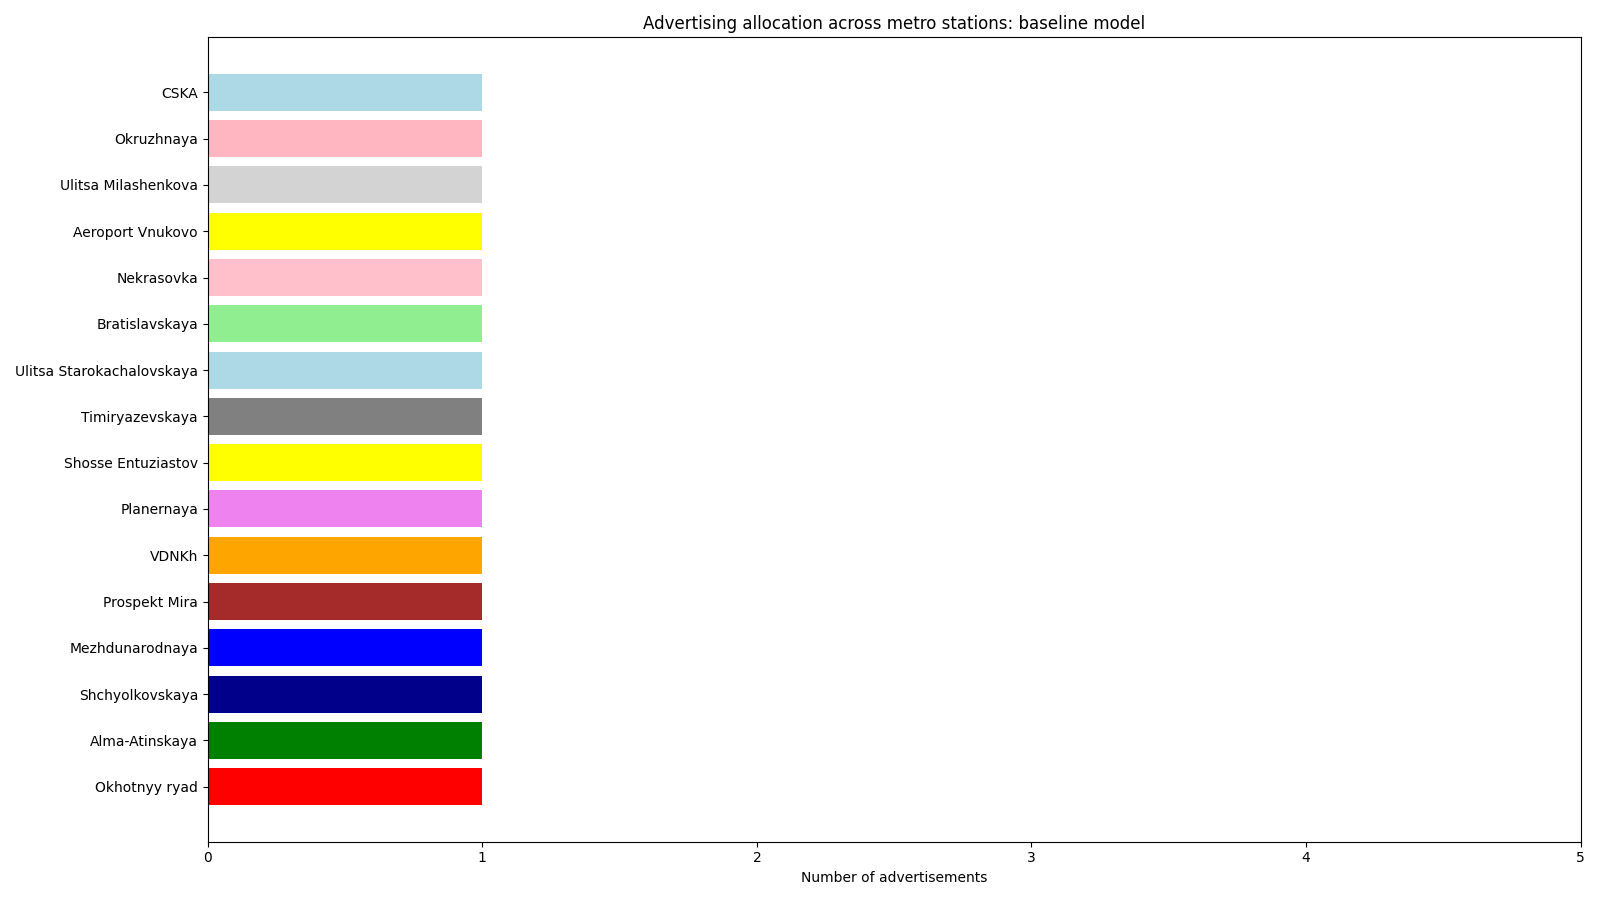

In [ ]:
fig, ax = plt.subplots(figsize =(16, 9))
names, counts = zip(*dict(ans_array).items())

custom_color = ["red", "green", "darkblue", "blue", "brown", "orange", "violet","yellow", "grey","lightblue", "lightgreen","pink", "yellow", "lightgrey", "lightpink", "lightblue"]

ax.barh(names, counts, color=custom_color)

ax.set_title('Advertising allocation across metro stations: baseline model')

plt.xticks(range(6))
plt.show()


**Conclusion:** Most stations selected for advertising are outside the city center. Nevertheless, the solution includes two major central stations, Okhotny Ryad and Prospekt Mira, despite their higher advertising costs, to attract more students. Overall, this approach helps minimize costs while increasing reach.

# Algorithm variations

## 1. Increasing student capacity
*From 100,000 to 500,000 students*

In [ ]:
ans = cp.Variable((31,16),integer = True)
obj_1 = cp.Maximize(100*(cp.sum(cp.multiply(cp.multiply(matrix,matrix_conversions),ans))) - cp.sum(cp.multiply(matrix_costs,ans)))
constraints_1 = [
    cp.sum(cp.multiply(matrix_costs,ans)) <= 15000000,
    cp.sum(cp.multiply(cp.multiply(matrix,matrix_conversions),ans)) <= 500000
]
for i in range(31):
    for j in range(16):
        constraints_1.append(ans[i][j] <=5)
        constraints_1.append(ans[i][j] >=0)
        constraints_1.append(ans[i][j] <=matrix[i][j])
for k in range(16):
    constraints_1.append(cp.sum(ans[:,k]) >= 1)

problem_1 = cp.Problem(obj_1, constraints_1)
problem_1.solve()
ans_1 = obj_1.value
print('Stations selected for advertising:','\n')
print(ans.value,'\n')
print(f'Total profit (RUB): {ans_1}')

Stations selected for advertising: 

[[0. 1. 0. 0. 1. 5. 0. 1. 1. 1. 2. 1. 1. 0. 1. 0.]
 [5. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 3. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 5. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0

In [ ]:
ans_array = []
for i in range(16):
    data = metro_actual_2[metro_actual_2['Line_id'] == i+1]
    for j in range(31):
        if ans.value[j][i]!=0:
             ans_array.append((data.iloc[j]['NameOfStation'],ans.value[j][i]))
        else:
             continue
print('Stations selected for advertising:','\n')
for i in range(len(ans_array)):
    print(ans_array[i],'\n')

Stations selected for advertising: 

('Yugo-Zapadnaya', 5.0) 

('Domodedovskaya', 1.0) 

('Baumanskaya', 3.0) 

('Vystavochnaya', 1.0) 

('Komsomolskaya', 1.0) 

('VDNKh', 5.0) 

('Tekstilshchiki', 5.0) 

('Novogireevo', 1.0) 

('Bulvar Dmitriya Donskogo', 1.0) 

('Ulitsa Starokachalovskaya', 1.0) 

('Lyublino', 2.0) 

('Nekrasovka', 1.0) 

('Rasskazovka', 1.0) 

('Timiryazevskaya', 1.0) 

('Rostokino', 1.0) 

('Tekstilshchiki', 1.0) 



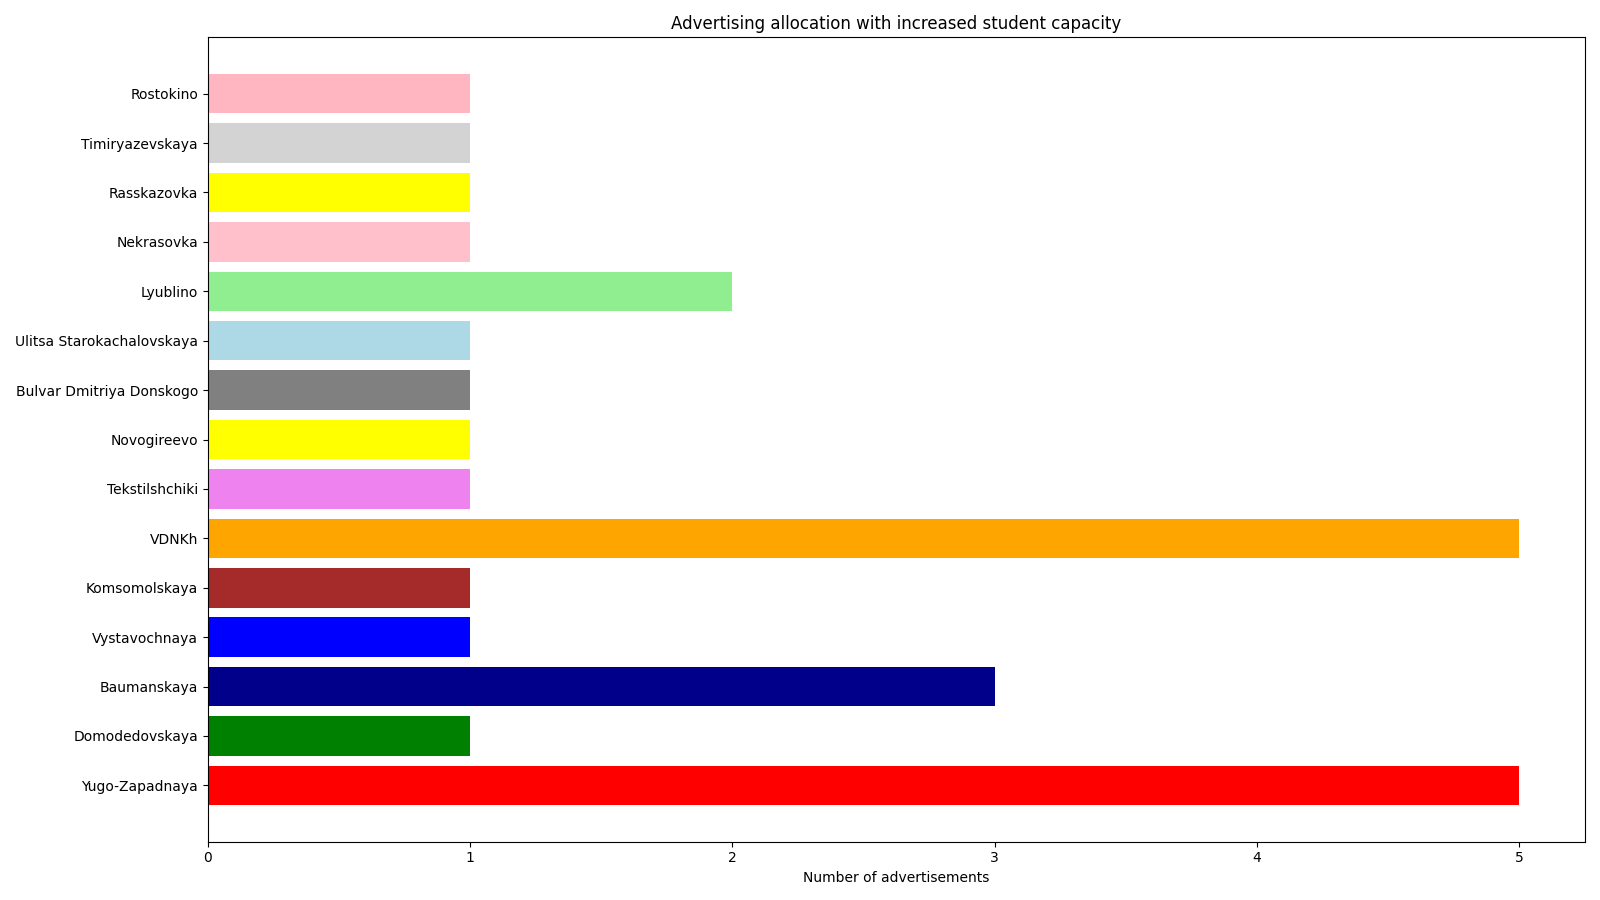

In [ ]:
fig, ax = plt.subplots(figsize =(16, 9))
names, counts = zip(*dict(ans_array).items())

ax.barh(names, counts, color=custom_color)

ax.set_title('Advertising allocation with increased student capacity')

plt.show()

**Conclusion:** The allocation changes considerably compared with the baseline: more stations with high passenger traffic are selected, including Komsomolskaya, Timiryazevskaya, and VDNKh. When the potential number of students increases substantially, the benefits of higher passenger traffic outweigh the higher advertising costs. Profit also increases by a larger factor than student capacity.

## 2. Changing advertising costs
*From RUB 150,000 to RUB 125,000 in the central zone, inside the Circle Line*

In [ ]:
for station in stations:
  if station in in_ring:
    metro_actual_2.loc[metro_actual_2['NameOfStation'] == station, 'Cost'] = 125000
  elif station in in_bkl:
    metro_actual_2.loc[metro_actual_2['NameOfStation'] == station, 'Cost'] = 100000
  else:
    metro_actual_2.loc[metro_actual_2['NameOfStation'] == station, 'Cost'] = 75000

In [ ]:
list_ = [[]] * 16
for i in range(len(metro_actual_2)):
  list_[metro_actual_2.iloc[i]['Line_id'] - 1] = list_[metro_actual_2.iloc[i]['Line_id'] - 1] + [metro_actual_2.iloc[i]['Cost']]

matrix_costs = np.zeros((31,16))
for i in range(16):
  for j in range(len(list_[i])):
    matrix_costs[j][i] = list_[i][j]


In [ ]:
ans = cp.Variable((31,16),integer = True)
obj_1 = cp.Maximize(100*(cp.sum(cp.multiply(cp.multiply(matrix,matrix_conversions),ans))) - cp.sum(cp.multiply(matrix_costs,ans)))
constraints_1 = [
    cp.sum(cp.multiply(matrix_costs,ans)) <= 15000000,
    cp.sum(cp.multiply(cp.multiply(matrix,matrix_conversions),ans)) <= 100000
]
for i in range(31):
    for j in range(16):
        constraints_1.append(ans[i][j] <=5)
        constraints_1.append(ans[i][j] >=0)
        constraints_1.append(ans[i][j] <=matrix[i][j])
for k in range(16):
    constraints_1.append(cp.sum(ans[:,k]) >= 1)

problem_1 = cp.Problem(obj_1, constraints_1)
problem_1.solve()
ans_1 = obj_1.value
print('Stations selected for advertising:','\n')
print(ans.value,'\n')
print(f'Total profit (RUB): {ans_1}')

Stations selected for advertising: 

[[1. 0. 0. 0. 1. 0. 0. 0. 0. 1. 0. 1. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0

In [ ]:
ans_array = []
for i in range(16):
    data = metro_actual_2[metro_actual_2['Line_id'] == i+1]
    for j in range(31):
        if ans.value[j][i]!=0:
             ans_array.append((data.iloc[j]['NameOfStation'],ans.value[j][i]))
        else:
             continue
print('Stations selected for advertising:','\n')
for i in range(len(ans_array)):
    print(ans_array[i],'\n')

Stations selected for advertising: 

('Okhotnyy ryad', 1.0) 

('Sokol', 1.0) 

('Myakinino', 1.0) 

('Vystavochnaya', 1.0) 

('Komsomolskaya', 1.0) 

('Medvedkovo', 1.0) 

('Spartak', 1.0) 

('Perovo', 1.0) 

('Otradnoe', 1.0) 

('Ulitsa Starokachalovskaya', 1.0) 

('Fiztekh', 1.0) 

('Nekrasovka', 1.0) 

('Ozyornaya', 1.0) 

('Vystavochnyy tsentr', 1.0) 

('Streshnevo', 1.0) 

('Novatorskaya', 1.0) 



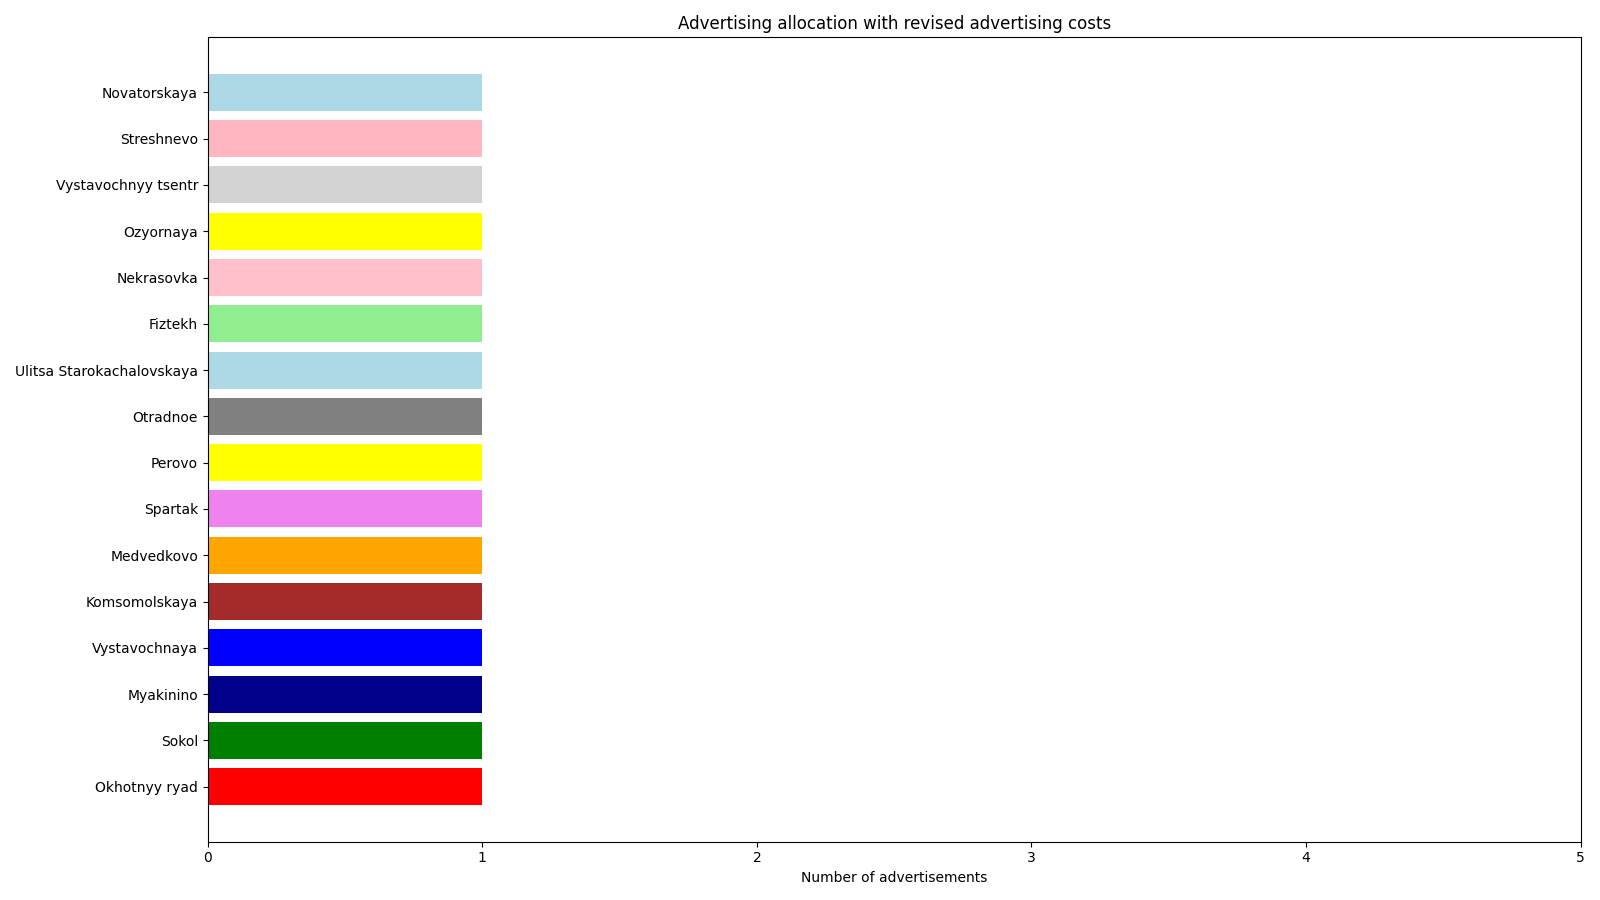

In [ ]:
fig, ax = plt.subplots(figsize =(16, 9))
names, counts = zip(*dict(ans_array).items())

ax.barh(names, counts, color=custom_color)

ax.set_title('Advertising allocation with revised advertising costs')

plt.xticks(range(6))
plt.show()

**Conclusion:** The allocation changes only slightly. Compared with the baseline, the solution includes more central stations with relatively expensive advertising, such as Komsomolskaya and Okhotny Ryad. Profit is also higher than in the baseline model.

## 3. Changing the advertising budget
*From RUB 15 million to RUB 5 million*

In [ ]:
for station in stations:
  if station in in_ring:
    metro_actual_2.loc[metro_actual_2['NameOfStation'] == station, 'Cost'] = 150000
  elif station in in_bkl:
    metro_actual_2.loc[metro_actual_2['NameOfStation'] == station, 'Cost'] = 100000
  else:
    metro_actual_2.loc[metro_actual_2['NameOfStation'] == station, 'Cost'] = 75000

In [ ]:
list_ = [[]] * 16
for i in range(len(metro_actual_2)):
  list_[metro_actual_2.iloc[i]['Line_id'] - 1] = list_[metro_actual_2.iloc[i]['Line_id'] - 1] + [metro_actual_2.iloc[i]['Cost']]

matrix_costs = np.zeros((31,16))
for i in range(16):
  for j in range(len(list_[i])):
    matrix_costs[j][i] = list_[i][j]

In [ ]:
ans = cp.Variable((31,16),integer = True)
obj_1 = cp.Maximize(100*(cp.sum(cp.multiply(cp.multiply(matrix,matrix_conversions),ans))) - cp.sum(cp.multiply(matrix_costs,ans)))
constraints_1 = [
    cp.sum(cp.multiply(matrix_costs,ans)) <= 5000000,
    cp.sum(cp.multiply(cp.multiply(matrix,matrix_conversions),ans)) <= 100000
]
for i in range(31):
    for j in range(16):
        constraints_1.append(ans[i][j] <=5)
        constraints_1.append(ans[i][j] >=0)
        constraints_1.append(ans[i][j] <=matrix[i][j])
for k in range(16):
    constraints_1.append(cp.sum(ans[:,k]) >= 1)

problem_1 = cp.Problem(obj_1, constraints_1)
problem_1.solve()
ans_1 = obj_1.value
print('Stations selected for advertising:','\n')
print(ans.value,'\n')
print(f'Total profit (RUB): {ans_1}')

Stations selected for advertising: 

[[1. 0. 1. 0. 0. 1. 0. 0. 0. 1. 0. 1. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0

In [ ]:
ans_array = []
for i in range(16):
    data = metro_actual_2[metro_actual_2['Line_id'] == i+1]
    for j in range(31):
        if ans.value[j][i]!=0:
             ans_array.append((data.iloc[j]['NameOfStation'],ans.value[j][i]))
        else:
             continue
print('Stations selected for advertising:','\n')
for i in range(len(ans_array)):
    print(ans_array[i],'\n')

Stations selected for advertising: 

('Okhotnyy ryad', 1.0) 

('Alma-Atinskaya', 1.0) 

('Shchyolkovskaya', 1.0) 

('Mezhdunarodnaya', 1.0) 

('Prospekt Mira', 1.0) 

('VDNKh', 1.0) 

('Planernaya', 1.0) 

('Shosse Entuziastov', 1.0) 

('Timiryazevskaya', 1.0) 

('Ulitsa Starokachalovskaya', 1.0) 

('Bratislavskaya', 1.0) 

('Nekrasovka', 1.0) 

('Aeroport Vnukovo', 1.0) 

('Ulitsa Milashenkova', 1.0) 

('Okruzhnaya', 1.0) 

('CSKA', 1.0) 



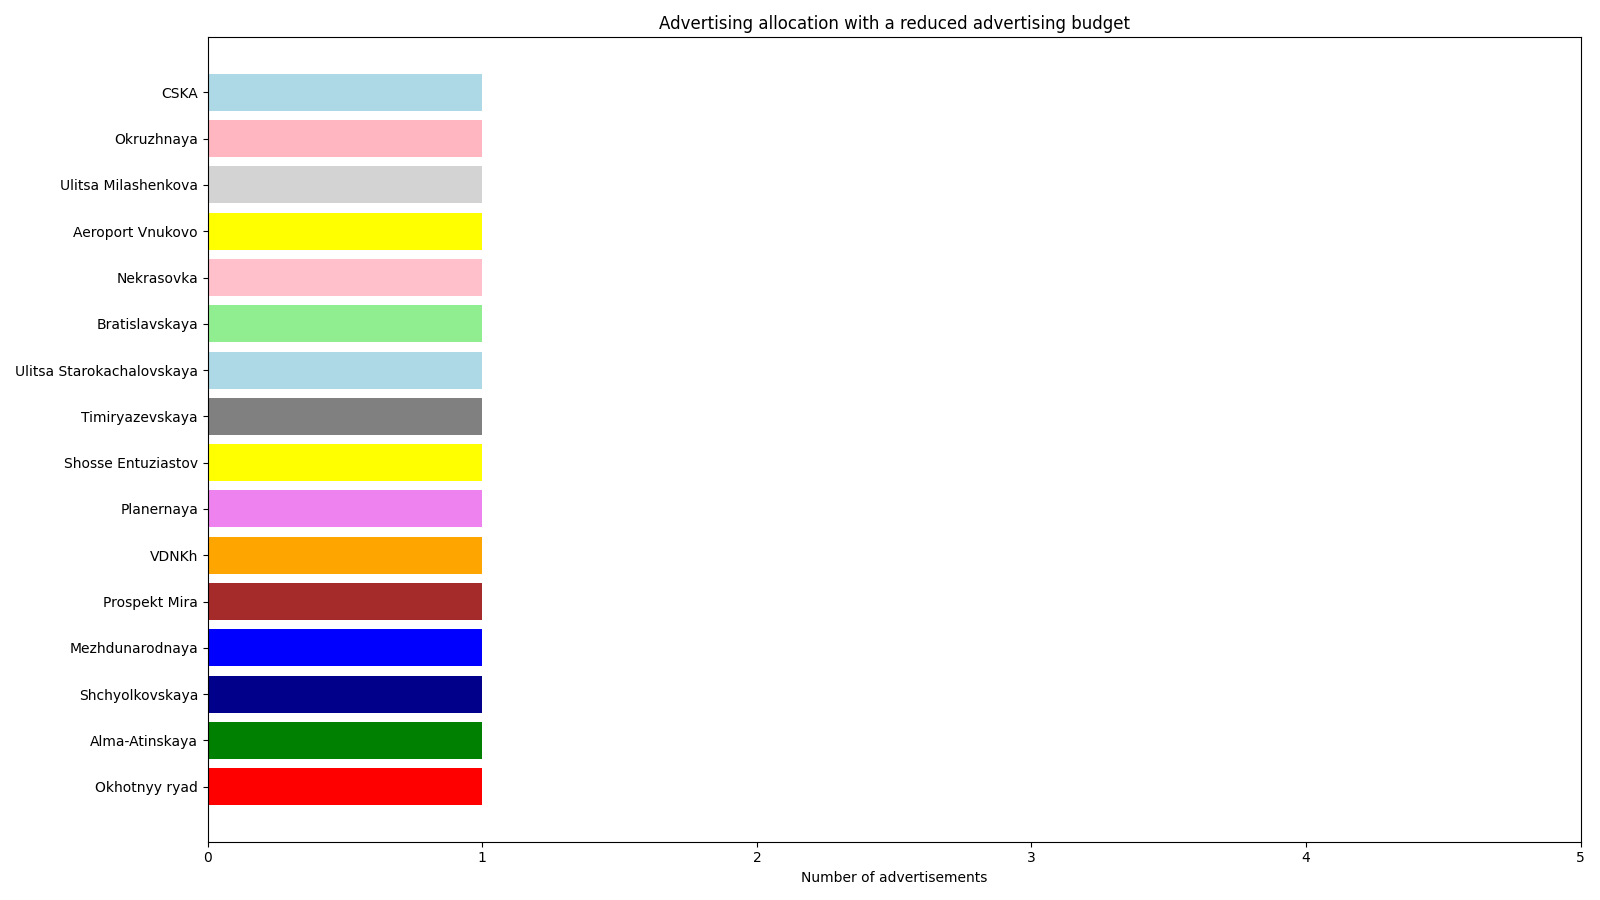

In [ ]:
fig, ax = plt.subplots(figsize =(16, 9))
names, counts = zip(*dict(ans_array).items())

ax.barh(names, counts, color=custom_color)

ax.set_title('Advertising allocation with a reduced advertising budget')

plt.xticks(range(6))
plt.show()

**Conclusion:** The solution is identical to the baseline allocation. With the original student capacity of 100,000, increasing advertising expenditure by placing advertisements at stations with greater student acquisition potential does not increase the difference between revenue and costs (profit). The optimal allocation therefore remains unchanged when the advertising budget is reduced by a factor of three at this student capacity.

# Extending the algorithm

We extend the model by introducing coefficients representing students' propensity to purchase the company's courses based on their university's ranking. We assume that students at the top-ranked university are more interested in the courses, so stations serving its campuses or dormitories receive a coefficient of 1.5. Stations serving universities ranked second, third, fourth, and fifth receive coefficients of 1.4, 1.3, 1.2, and 1.1, respectively.

*If a station serves several top-five universities, it receives the coefficient associated with the highest-ranked university.*

We load a new table and apply transformations similar to those used earlier:

In [ ]:
url = 'https://raw.githubusercontent.com/TatianaSoboleva/-/main/uni_and_dorms_new.csv'
unidorms = pd.read_csv(url, delimiter = ',')
unidorms = normalize_dataframe(unidorms)
unidorms.head()
def f(row):
  if row['Rating'] == 1:
      return 1.5
  elif row['Rating'] == 2:
      return 1.4
  elif row['Rating'] == 3:
      return 1.3
  elif row['Rating'] == 4:
      return 1.2
  else :
      return 1.1
unidorms['Rating_coef'] = unidorms.apply(f, axis=1)
unidorms.head(5)

,Name,Metro,Rating,Rating_coef
0,Moskovskiy gosudarstvennyy universitet imeni M...,Universitet,1,1.5
1,Moskovskiy gosudarstvennyy universitet imeni M...,Biblioteka imeni Lenina,1,1.5
2,Moskovskiy gosudarstvennyy universitet imeni M...,Okhotnyy ryad,1,1.5
3,Moskovskiy gosudarstvennyy tekhnicheskiy univers...,Baumanskaya,2,1.4
4,Moskovskiy gosudarstvennyy tekhnicheskiy univers...,Rechnoy vokzal,2,1.4


In [ ]:
unidorms_1 = unidorms['Metro'].value_counts().to_frame()
unidorms_1.reset_index(inplace= True)
unidorms_1 = unidorms_1.rename(columns={'index': 'NameStation', 'Metro': 'Quantity'})

unidorms_pred = unidorms[['Metro','Rating_coef']]
unidorms_2 = unidorms_pred.groupby(['Metro']).max()
unidorms_2.reset_index(inplace= True)
unidorms_2 = unidorms_2.rename(columns={'Metro': 'NameStation'})
unidorms_2.head(5)

,NameStation,Rating_coef
0,Aviamotornaya,1.3
1,Baumanskaya,1.4
2,Biblioteka imeni Lenina,1.5
3,VDNKh,1.3
4,Vladykino,1.2


In [ ]:
metro_actual_2 = metro_actual_2.merge(unidorms_2, left_on = 'NameOfStation', right_on = 'NameStation', how = 'left')

In [ ]:
metro_actual_2['Rating_coef'] = metro_actual_2['Rating_coef'].fillna(1)
metro_actual_2.head(5)

,NameOfStation,Line,Year,Quarter,IncomingPassengers,OutgoingPassengers,global_id,Unnamed: 7,Line_id,Cost,NameStation_x,Quantity,university_flg,conversions_1,NameStation_y,Rating_coef
0,Komsomolskaya,Koltsevaya liniya,2023,III quarter,8420305.0,6691692.0,2630091456,NaN,5,150000.0,Komsomolskaya,2.0,1,0.004,Komsomolskaya,1.3
1,VDNKh,Kaluzhsko-Rizhskaya liniya,2023,III quarter,6811166.0,6378959.0,2625907197,NaN,6,75000.0,VDNKh,1.0,1,0.003,VDNKh,1.3
2,Shchyolkovskaya,Arbatsko-Pokrovskaya liniya,2023,III quarter,6304487.0,5922637.0,2625907121,NaN,3,75000.0,NaN,NaN,1,0.002,NaN,1.0
3,Novogireevo,Kalininskaya liniya,2023,III quarter,5650771.0,5472536.0,2625907186,NaN,8,75000.0,NaN,NaN,1,0.002,NaN,1.0
4,Vykhino,Tagansko-Krasnopresnenskaya liniya,2023,III quarter,5445897.0,5212132.0,2625907480,NaN,7,75000.0,NaN,NaN,1,0.002,NaN,1.0


Matrix of university ranking coefficients

In [ ]:
list_ = [[]] * 16
for i in range(len(metro_actual_2)):
  list_[metro_actual_2.iloc[i]['Line_id'] - 1] = list_[metro_actual_2.iloc[i]['Line_id'] - 1] + [metro_actual_2.iloc[i]['Rating_coef']]

matrix_universities = np.zeros((31,16))
for i in range(16):
  for j in range(len(list_[i])):
    matrix_universities[j][i] = list_[i][j]

matrix_universities

array([[1.5, 1. , 1. , 1. , 1.3, 1.3, 1. , 1. , 1. , 1. , 1.3, 1. , 1. ,
        1. , 1. , 1. ],
       [1.2, 1. , 1. , 1. , 1.3, 1.3, 1.3, 1. , 1. , 1. , 1. , 1. , 1. ,
        1. , 1. , 1. ],
       [1. , 1. , 1.4, 1. , 1. , 1. , 1. , 1. , 1. , 1. , 1. , 1. , 1. ,
        1. , 1. , 1. ],
       [1. , 1. , 1. , 1. , 1. , 1. , 1. , 1.3, 1. , 1. , 1. , 1. , 1. ,
        1. , 1. , 1. ],
       [1.3, 1. , 1. , 1. , 1.2, 1. , 1.3, 1.3, 1. , 1. , 1.3, 1. , 1. ,
        1. , 1. , 1.3],
       [1.5, 1. , 1. , 1. , 1.3, 1.3, 1. , 1. , 1. , 1. , 1. , 1.3, 1. ,
        1. , 1. , 1. ],
       [1.3, 1.2, 1. , 1. , 1. , 1. , 1. , 1.3, 1. , 1. , 1. , 1. , 1. ,
        0. , 1. , 1.4],
       [1.5, 1.3, 1.4, 1. , 1. , 1. , 1. , 1. , 1. , 0. , 1. , 1. , 1. ,
        0. , 1. , 1. ],
       [1.3, 1. , 1.3, 1. , 1. , 1. , 1. , 0. , 1. , 0. , 1. , 0. , 1. ,
        0. , 1. , 1. ],
       [1. , 1. , 1. , 1. , 1. , 1. , 1. , 0. , 1. , 0. , 1. , 0. , 1. ,
        0. , 1. , 1. ],
       [1.3, 1. , 1. , 1.3, 1.

In [ ]:
ans = cp.Variable((31,16),integer = True)
obj_2 = cp.Maximize(100*cp.sum(cp.multiply(cp.multiply(cp.multiply(matrix,matrix_conversions),matrix_universities),ans)) - cp.sum(cp.multiply(matrix_costs,ans)))
constraints_2 = [
    cp.sum(cp.multiply(matrix_costs,ans)) <= 15000000,
    cp.sum(cp.multiply(cp.multiply(matrix,matrix_conversions),ans)) <= 100000
]
for i in range(31):
    for j in range(16):
        constraints_2.append(ans[i][j] <=5)
        constraints_2.append(ans[i][j] >=0)
        constraints_2.append(ans[i][j] <=matrix[i][j])
for k in range(16):
    constraints_2.append(cp.sum(ans[:,k]) >= 1)

problem_2 = cp.Problem(obj_2, constraints_2)
problem_2.solve()
ans_2 = obj_2.value
print('Stations selected for advertising:','\n')
print(ans.value,'\n')
print(f'Total profit (RUB): {ans_2}')

Stations selected for advertising: 

[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [3. 0. 0. 0. 1. 0. 0. 0. 0. 1. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0

In [ ]:
ans_array = []
for i in range(16):
    data = metro_actual_2[metro_actual_2['Line_id'] == i+1]
    for j in range(31):
        if ans.value[j][i]!=0:
             ans_array.append((data.iloc[j]['NameOfStation'],ans.value[j][i]))
        else:
             continue
print('Stations selected for advertising:','\n')
for i in range(len(ans_array)):
    print(ans_array[i],'\n')

Stations selected for advertising: 

('Universitet', 3.0) 

('Rechnoy vokzal', 1.0) 

('Izmaylovskaya', 1.0) 

('Kuntsevskaya', 1.0) 

('Kurskaya', 1.0) 

('Yasenevo', 1.0) 

('Spartak', 1.0) 

('Shosse Entuziastov', 1.0) 

('Sevastopolskaya', 1.0) 

('Lesoparkovaya', 1.0) 

('Fiztekh', 1.0) 

('Okskaya', 1.0) 

('Pykhtino', 1.0) 

('Ulitsa Sergeya Eyzenshteyna', 1.0) 

('Belokamennaya', 1.0) 

('Prospekt Vernadskogo', 1.0) 



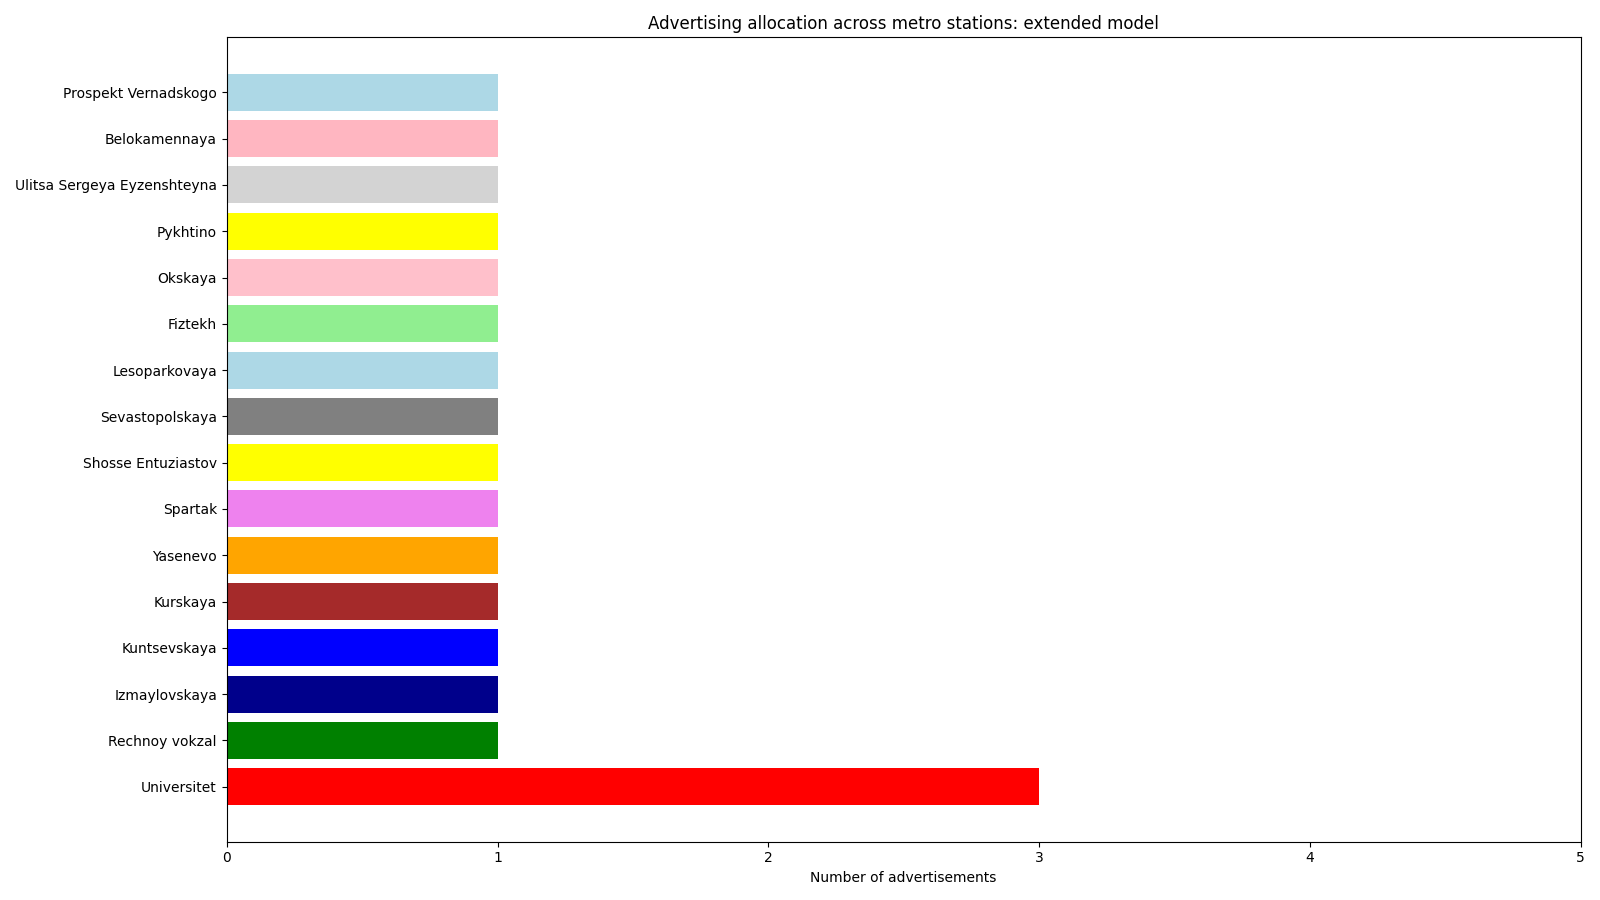

In [ ]:
fig, ax = plt.subplots(figsize =(16, 9))
names, counts = zip(*dict(ans_array).items())

ax.barh(names, counts, color=custom_color)

ax.set_title('Advertising allocation across metro stations: extended model')

plt.xticks(range(6))
plt.show()

**Conclusion:** The allocation changes relative to the baseline because advertising at stations serving the highest-ranked universities becomes more profitable. One example is Universitet, which serves several academic buildings and dormitories of Moscow State University, ranked first in the ranking used here. This additional assumption gives greater weight to stations serving universities, offsetting their higher advertising costs.

# Summary

1. The stations selected for advertising depend on several factors: advertising costs, the presence of nearby universities, and students' propensity to purchase courses.

2. When advertising in the center is relatively expensive, peripheral stations with high student acquisition potential, such as Tekstilshchiki, are the most attractive.

3. The size of the company recruiting students strongly affects station selection: larger companies can afford more expensive advertising at more popular locations.

4. The highest profit was achieved when the model's student capacity was increased.

5. This algorithm can be applied to similar problems aimed at increasing advertising reach in the Moscow Metro.